In [57]:
import re
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer

nltk.download('stopwords', quiet=True)

# Load dataset
url = 'https://raw.githubusercontent.com/mohammadrayangubat/Tag-Lish-NLP-30-Sentences-/refs/heads/main/nlp_dataset.csv'
df = pd.read_csv(url)
document = df["taglish_sent"]

#Step 1: Preprocessing the Text

Before applying the BoW model, we need to preprocess the text. This includes:
1. Converting the text to lowercase
2. Removing non-word characters
3. Removing extra spaces

All the preprocessing steps are considered in order to properly uniformatize the datasets. Additionally, custom stopwords are included in consideration of the Taglish Dataset

In [58]:
# Preprocessing: one row = one document
preprocessed_doc = []

for sentence in document:
    sentence = sentence.lower()                     # lowercase
    sentence = re.sub(r'\W|\d', ' ', sentence)      # remove non-word characters and numbers
    sentence = re.sub(r'\s+', ' ', sentence).strip()  # collapse extra whitespace
    preprocessed_doc.append(sentence)

In [59]:
# Custom Tagalog stopwords + English stopwords
tagalog_stopwords = {
    'ang', 'mga', 'si', 'ng', 'nang', 'at', 'o', 'dahil', 'kaya', 'kasi',
    'ako', 'ikaw', 'mo', 'dito', 'ni', 'na', 'sa', 'yung', 'kang', 'ka', 'lang', 'may',
    'ko', 'yun', 'pa', 'mas', 'naman', 'pwede', 'lahat', 'po', 'din', 'rin', 'pag', 'kapag'
}
custom_stopwords = list(tagalog_stopwords | set(stopwords.words('english')))

# TF-IDF
vectorizer = TfidfVectorizer(stop_words=custom_stopwords)
X = vectorizer.fit_transform(preprocessed_doc)
words = vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(X.toarray(), columns=words)
tfidf_df.index = [f"Sentence {i+1}" for i in range(len(preprocessed_doc))]
print(tfidf_df.round(3))

             abogado   agad   alam  aliases   also    alt  always  areas  \
Sentence 1     0.000  0.000  0.000    0.000  0.000  0.000   0.000  0.000   
Sentence 2     0.000  0.000  0.000    0.000  0.000  0.408   0.000  0.000   
Sentence 3     0.000  0.000  0.000    0.000  0.000  0.000   0.000  0.000   
Sentence 4     0.000  0.000  0.000    0.000  0.000  0.000   0.000  0.000   
Sentence 5     0.000  0.000  0.000    0.000  0.000  0.000   0.000  0.000   
Sentence 6     0.000  0.374  0.000    0.000  0.000  0.000   0.000  0.000   
Sentence 7     0.000  0.000  0.000    0.000  0.000  0.000   0.000  0.000   
Sentence 8     0.000  0.000  0.178    0.000  0.000  0.000   0.000  0.000   
Sentence 9     0.000  0.000  0.000    0.000  0.000  0.000   0.000  0.000   
Sentence 10    0.000  0.000  0.000    0.000  0.000  0.000   0.000  0.000   
Sentence 11    0.000  0.000  0.000    0.000  0.000  0.000   0.000  0.000   
Sentence 12    0.000  0.000  0.000    0.000  0.000  0.000   0.000  0.000   
Sentence 13 

In [60]:
# Table of most prominent words with weights
total_w = tfidf_df.sum()
summary = pd.DataFrame({
    "Total TF-IDF": total_w,
    "Mean TF-IDF": tfidf_df.mean(),
    "Doc Freq": (tfidf_df > 0).sum(),
    "Relative Weight (%)": total_w / total_w.sum() * 100,
}).sort_values("Total TF-IDF", ascending=False)

top_n = 15
print(summary.head(top_n).round(4))

             Total TF-IDF  Mean TF-IDF  Doc Freq  Relative Weight (%)
click              1.1320       0.0377         4               1.2993
kayo               0.9450       0.0315         2               1.0846
gamit              0.8845       0.0295         2               1.0151
para               0.8188       0.0273         4               0.9397
mag                0.7839       0.0261         3               0.8998
baha               0.7556       0.0252         3               0.8672
kung               0.7334       0.0244         4               0.8418
syempre            0.7163       0.0239         1               0.8222
naging             0.7013       0.0234         2               0.8049
prosecution        0.6946       0.0232         2               0.7972
code               0.6870       0.0229         3               0.7885
experience         0.6755       0.0225         2               0.7754
ba                 0.6552       0.0218         2               0.7520
hide               0

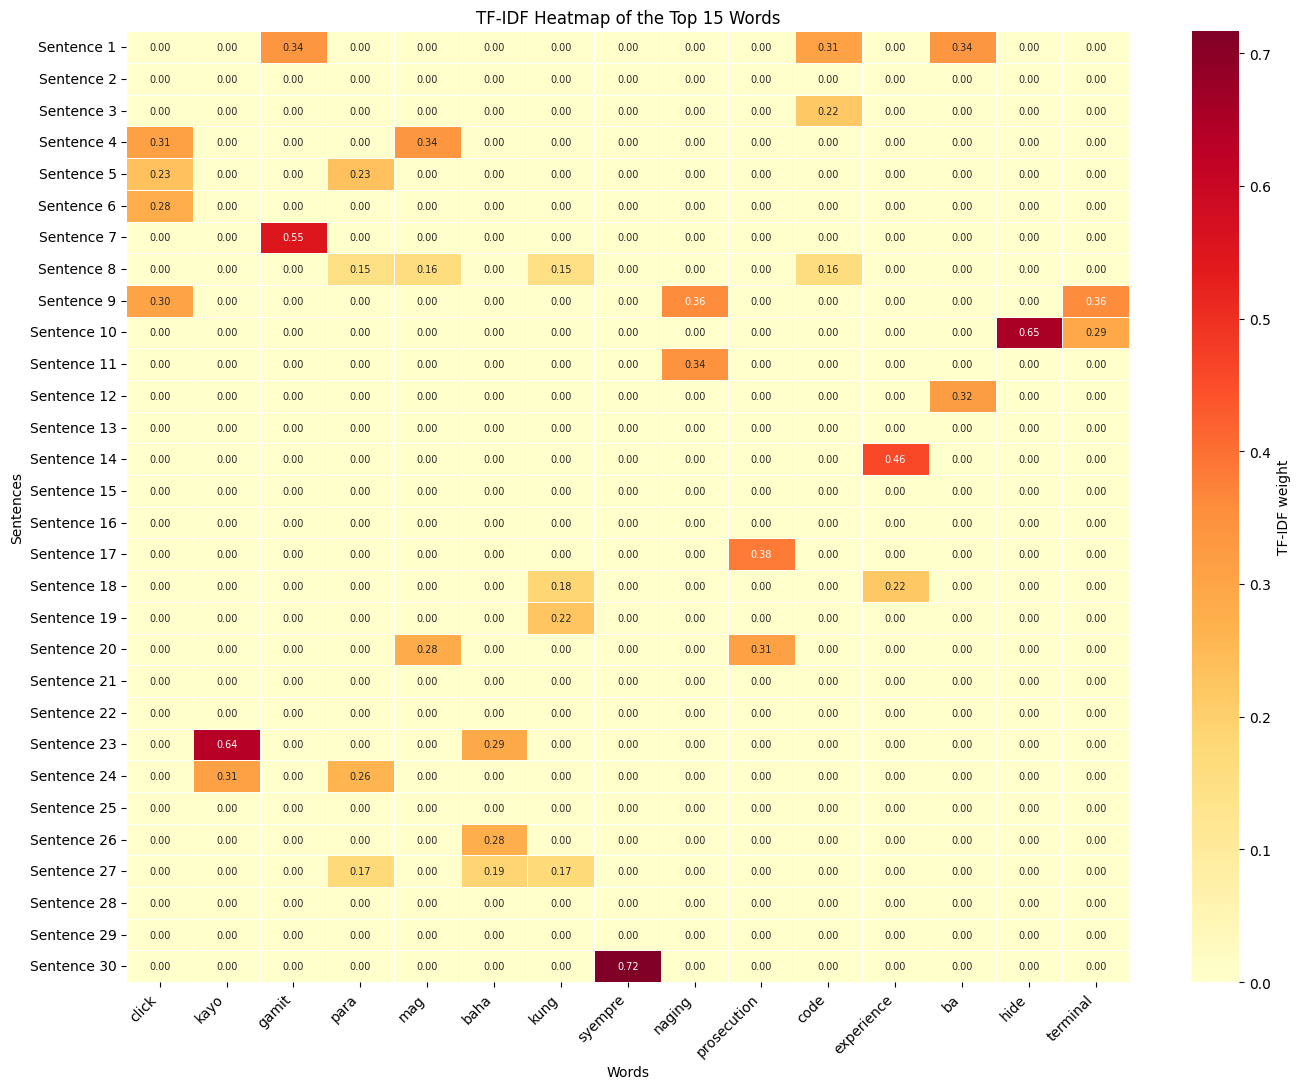

In [61]:
# Heatmap of TF-IDF weights
top_words = summary.head(top_n).index
plt.figure(figsize=(14, 11))
sns.heatmap(tfidf_df[top_words], cmap="YlOrRd", annot=True, fmt=".2f", linewidths=0.4,
            cbar_kws={"label": "TF-IDF weight"}, annot_kws={"size": 7})
plt.title(f"TF-IDF Heatmap of the Top {top_n} Words")
plt.xlabel("Words")
plt.ylabel("Sentences")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

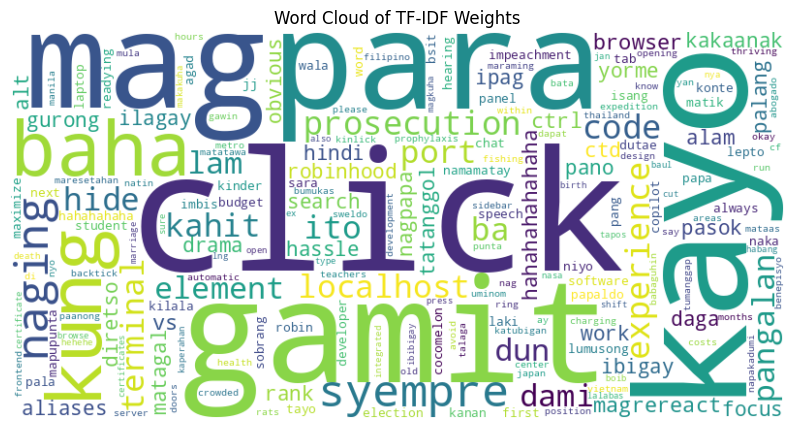

In [62]:
from wordcloud import WordCloud

wordcloud = WordCloud(width=800, height=400, background_color='white') \
    .generate_from_frequencies(total_w.to_dict())
plt.figure(figsize=(10, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Word Cloud of TF-IDF Weights")
plt.show()

#Preprocessing Steps

* Lowercasing: unifies “Click” and “click”.
* Removing non-word characters and digits: removes punctuation and symbols, with the Python regex \W|\d.
* Whitespace collapsing: tidies the leftover gaps.
* Stopword removal: NLTK’s English list plus your custom Tagalog list, since NLTK has no Tagalog stopwords and the dataset is code-switched.
* Tokenization: done by TfidfVectorizer itself.